# Finding early galaxies with LAPIS

Move a young FSPS galaxy spectrum through the **F150W2, F277W and F444W** bandpasses and show the corresponding circular Sérsic galaxy images. Run from the LAPIS directory with the `mistc3k-prospect-dev` environment (FSPS, sedpy, GalSim, Matplotlib and Pillow).

Every frame has **F444W flux density normalised to one**. Angular size, PSF, background noise and image stretch remain fixed, so changes in the stamps trace the changing colours rather than cosmological dimming. The same 50 Myr stellar population is moved through redshift; this is not an evolving galaxy model.

Hydrogen absorption is an idealised zero-transmission step below rest-frame 1216 Å, not a reionisation or damping-wing calculation. F150W2 retains some transmitted continuum at z = 16 because its red edge extends beyond the break. A faint band is not automatically a non-detection: the background here is illustrative, not a LAPIS depth model.

In [20]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.colors import AsinhNorm
from IPython.display import Image as DisplayImage, display

import fsps
import galsim
from sedpy.observate import getSED, load_filters

## Configure the demonstration

Edit this cell, then rerun the cells below. Radii and PSF FWHM are in arcseconds. The default uses the **same illustrative Gaussian PSF** in all bands to isolate colour changes; edit `PSF_FWHM_ARCSEC` to use different widths, or use zero for an unconvolved profile. There is no shear or rotation.

`NOISE_SIGMA` is the background RMS per pixel in units where the total F444W model flux is one. Set it to zero for noiseless stamps. Each band has its own fixed background realisation. All bands and frames share a single image stretch.

In [37]:
FILTER_NAMES = ["jwst_f150w2", "jwst_f277w", "jwst_f444w"]
FILTER_LABELS = ["F150W2", "F277W", "F444W"]
FILTER_COLOURS = ["royalblue", "darkorange", "crimson"]

REDSHIFTS = np.linspace(10.0, 20.0, 101)
POPULATION_AGE_GYR = 0.05
LOGZSOL = -1.0
DUST2 = 0.0
BREAK_REST_AA = 1216.0
WAVELENGTH_LIMITS_UM = (0.7, 5.3)

SERSIC_N = 1.0
HALF_LIGHT_RADIUS_ARCSEC = 0.10
PIXEL_SCALE_ARCSEC = 0.03
IMAGE_SIZE = 48
PSF_FWHM_ARCSEC = [0.10, 0.10, 0.10]
NOISE_SIGMA = 0.0004
RANDOM_SEED = 17
IMAGE_STRETCH_FRACTION = 0.1

FPS = 10
END_HOLD_SECONDS = 1.5
FIGURE_SIZE = (12.8, 7.2)
ANIMATION_DPI = 300
PREVIEW_REDSHIFT = 18.0
SAVE_GIF = True
SAVE_PREVIEW = True

LAPIS_DIR = Path.cwd()
if not (LAPIS_DIR / "figures").is_dir():
    LAPIS_DIR = LAPIS_DIR.parents[2]

FIGURE_DIR = LAPIS_DIR / "figures" / "outreach"
GIF_PATH = FIGURE_DIR / "lapis_lyman_dropout.gif"
PREVIEW_PATH = FIGURE_DIR / "lapis_lyman_dropout_preview.png"

## Generate the spectrum and synthetic photometry

Use a constant star formation history, no nebular emission and no FSPS IGM attenuation. Apply the hydrogen step explicitly after shifting the spectrum. FSPS returns rest-frame luminosity per Å; the common luminosity-to-flux factor cancels when dividing by F444W. The conversion from per-Å to per-Hz is applied before plotting.

The dots are **band-averaged flux densities**, plotted at the filter pivot wavelengths. They are not monochromatic samples of the spectrum. Throughputs are the unscaled sedpy curves. The wavelength grid covers all three bandpasses, including their low-throughput wings.

In [22]:
filters = load_filters(FILTER_NAMES)
filter_pivot_um = np.array([band.wave_pivot / 1e4 for band in filters])
reference_index = FILTER_LABELS.index("F444W")

population = fsps.StellarPopulation(
    zcontinuous=1, sfh=1, const=1.0, logzsol=LOGZSOL,
    dust2=DUST2, add_igm_absorption=False, add_neb_emission=False,
)
wave_rest_aa, luminosity_lambda = population.get_spectrum(tage=POPULATION_AGE_GYR, peraa=True)

# Cover the complete filters, even if the plotting window is narrower
wave_min_aa = min(band.wavelength.min() for band in filters)
wave_max_aa = max(band.wavelength.max() for band in filters)
wave_min_aa = min(wave_min_aa, WAVELENGTH_LIMITS_UM[0] * 1e4)
wave_max_aa = max(wave_max_aa, WAVELENGTH_LIMITS_UM[1] * 1e4)
wave_obs_aa = np.linspace(wave_min_aa, wave_max_aa, 8000)
wave_obs_um = wave_obs_aa / 1e4

In [23]:
def calculate_redshift_sequence(redshifts, wave_obs_aa, wave_rest_aa, luminosity_lambda, filters, reference_index):
    """Calculate spectra and band fluxes normalised to a reference band.

    Parameters
    ----------
    redshifts : array_like
        Redshifts at which to place the same stellar population.
    wave_obs_aa : ndarray
        Observed wavelength grid in Angstroms covering all filters.
    wave_rest_aa : ndarray
        Rest wavelength grid in Angstroms from FSPS.
    luminosity_lambda : ndarray
        Rest-frame luminosity per Angstrom from FSPS.
    filters : list
        Loaded sedpy filters, including the reference band.
    reference_index : int
        Index of the band held at unit flux density.

    Returns
    -------
    sequence : dict
        Normalised f_nu spectra, unabsorbed spectra, band flux densities
        and observed break wavelengths for every redshift.
    """

    spectra = []
    unabsorbed_spectra = []
    band_fluxes = []
    for redshift in redshifts:
        rest_grid_aa = wave_obs_aa / (1.0 + redshift)
        flux_lambda = np.interp(rest_grid_aa, wave_rest_aa, luminosity_lambda) / (1.0 + redshift)
        absorbed_flux_lambda = flux_lambda * (rest_grid_aa >= BREAK_REST_AA)

        # Allow exact zero flux in a fully absorbed band
        with np.errstate(divide="ignore"):
            maggies = np.asarray(getSED(wave_obs_aa, absorbed_flux_lambda, filters, linear_flux=True))
        reference_fnu = maggies[reference_index] * 3631e-23
        if reference_fnu <= 0 or not np.isfinite(reference_fnu):
            raise ValueError(f"The reference band has no transmitted flux at z={redshift:.2f}")

        spectra.append(absorbed_flux_lambda * wave_obs_aa**2 / 2.99792458e18 / reference_fnu)
        unabsorbed_spectra.append(flux_lambda * wave_obs_aa**2 / 2.99792458e18 / reference_fnu)
        band_fluxes.append(maggies / maggies[reference_index])

    return {
        "spectra": np.asarray(spectra),
        "unabsorbed_spectra": np.asarray(unabsorbed_spectra),
        "band_fluxes": np.asarray(band_fluxes),
        "break_um": BREAK_REST_AA * (1.0 + np.asarray(redshifts)) / 1e4,
    }


sequence = calculate_redshift_sequence(REDSHIFTS, wave_obs_aa, wave_rest_aa, luminosity_lambda, filters, reference_index)
for redshift in [12.0, 16.0, 18.0, 20.0]:
    frame_index = np.argmin(np.abs(REDSHIFTS - redshift))
    print(f"z = {REDSHIFTS[frame_index]:4.1f}: F150W2, F277W, F444W = {sequence['band_fluxes'][frame_index].round(3)}")

z = 12.0: F150W2, F277W, F444W = [0.854 1.335 1.   ]
z = 16.0: F150W2, F277W, F444W = [0.256 1.356 1.   ]
z = 18.0: F150W2, F277W, F444W = [0.05  1.326 1.   ]
z = 20.0: F150W2, F277W, F444W = [0.    1.033 1.   ]


## Render circular Sérsic galaxy stamps

Draw one unit-flux profile per band with GalSim, optionally convolved with a Gaussian PSF. Multiply these templates by the synthetic band fluxes in each animation frame. The same circular morphology is used in every band, with fixed angular half-light radius. This follows the Sérsic → convolution → `drawImage` approach in the existing mock-generation notebooks, without their bulge–disc or shear parameters.

GalSim integrates the profile over the pixels (`method="auto"`). The finite stamp can miss the outer wings, particularly if you increase the Sérsic index or radius; increase `IMAGE_SIZE` if needed. No per-stamp renormalisation or automatic image stretching is applied.

In [24]:
def render_sersic_templates(sersic_n, half_light_radius_arcsec, psf_fwhm_arcsec, pixel_scale_arcsec, image_size):
    """Render circular, unit-total-flux galaxy profiles for each band.

    Parameters
    ----------
    sersic_n : float
        Sérsic index of the circular galaxy model.
    half_light_radius_arcsec : float
        Angular half-light radius in arcseconds.
    psf_fwhm_arcsec : array_like
        Gaussian PSF FWHM per band in arcseconds; zero skips convolution.
    pixel_scale_arcsec : float
        Pixel size in arcseconds.
    image_size : int
        Number of pixels along each side of the square stamp.

    Returns
    -------
    templates : ndarray
        Pixel-integrated images with shape (number of bands, size, size).
        Flux outside the finite stamp is not recovered.
    """

    galaxy = galsim.Sersic(n=sersic_n, half_light_radius=half_light_radius_arcsec, flux=1.0)
    templates = []
    for fwhm in psf_fwhm_arcsec:
        model = galaxy
        if fwhm > 0:
            model = galsim.Convolve([galaxy, galsim.Gaussian(fwhm=fwhm)])
        image = model.drawImage(nx=image_size, ny=image_size, scale=pixel_scale_arcsec, method="auto")
        templates.append(image.array.copy())
    return np.asarray(templates)


templates = render_sersic_templates(SERSIC_N, HALF_LIGHT_RADIUS_ARCSEC, PSF_FWHM_ARCSEC, PIXEL_SCALE_ARCSEC, IMAGE_SIZE)
random_generator = np.random.default_rng(RANDOM_SEED)
backgrounds = random_generator.normal(0.0, NOISE_SIGMA, templates.shape)
galaxy_images = sequence["band_fluxes"][:, :, None, None] * templates[None, :, :, :] + backgrounds[None, :, :, :]

# Keep one stretch for every band and redshift
image_vmax = np.max(sequence["band_fluxes"][:, :, None, None] * templates[None, :, :, :])
image_norm = AsinhNorm(linear_width=IMAGE_STRETCH_FRACTION * image_vmax, vmin=0.0, vmax=image_vmax)
print("Fraction of each unit-flux model inside the stamp:", templates.sum(axis=(1, 2)).round(5))

Fraction of each unit-flux model inside the stamp: [0.99996 0.99996 0.99996]


## Build the animation

The top panel shows the spectrum and filter-averaged photometry. The middle panel shows the fixed filter throughputs. The lower panels show the simulated images on a common brightness scale. Both the spectrum and the dots are in units of the F444W flux density.

In [34]:
plt.rcParams.update({"font.size": 12, "axes.labelsize": 13, "axes.titlesize": 15})
fig = plt.figure(figsize=FIGURE_SIZE, facecolor="white")
grid = fig.add_gridspec(3, 3, height_ratios=[1.8, 0.55, 2.2], hspace=0.55, wspace=0.22)
fig.subplots_adjust(left=0.075, right=0.99, bottom=0.04, top=0.98)
spectrum_ax = fig.add_subplot(grid[0, :])
filter_ax = fig.add_subplot(grid[1, :], sharex=spectrum_ax)
image_axes = [fig.add_subplot(grid[2, band_index]) for band_index in range(len(filters))]

unabsorbed_line, = spectrum_ax.plot(wave_obs_um, sequence["unabsorbed_spectra"][0], color="silver", ls="-", lw=1.2, label="Before hydrogen absorption")
spectrum_line, = spectrum_ax.plot(wave_obs_um, sequence["spectra"][0], color="black", lw=1.8, label="Observed spectrum")
photometry_points = spectrum_ax.scatter(filter_pivot_um, sequence["band_fluxes"][0], c=FILTER_COLOURS, s=85, edgecolors="white", zorder=5)
spectrum_break = spectrum_ax.axvline(sequence["break_um"][0], color="purple", ls="--", lw=1.6)
filter_break = filter_ax.axvline(sequence["break_um"][0], color="purple", ls="--", lw=1.6)
redshift_text = spectrum_ax.text(0.98, 0.92, "", transform=spectrum_ax.transAxes, ha="right", va="top", fontsize=14)

visible_wave = (wave_obs_um >= WAVELENGTH_LIMITS_UM[0]) & (wave_obs_um <= WAVELENGTH_LIMITS_UM[1])
spectrum_ymax = 1.25 * np.max(sequence["unabsorbed_spectra"][:, visible_wave])
spectrum_ax.set(xlim=WAVELENGTH_LIMITS_UM, ylim=(-0.05, spectrum_ymax), ylabel=r"Relative brightness ($f_\nu$)")
spectrum_ax.legend(loc="upper left", frameon=False, fontsize=10)
spectrum_ax.tick_params(labelbottom=False)
spectrum_ax.spines[["top", "right"]].set_visible(False)

throughput_max = max(band.transmission.max() for band in filters)
for band, label, colour in zip(filters, FILTER_LABELS, FILTER_COLOURS):
    filter_ax.fill_between(band.wavelength / 1e4, band.transmission, color=colour, alpha=0.35)
    filter_ax.plot(band.wavelength / 1e4, band.transmission, color=colour, lw=1.1)
    filter_ax.text(band.wave_pivot / 1e4, throughput_max * 1.07, label, color=colour, ha="center", fontsize=11)
filter_ax.set(ylim=(0.0, throughput_max * 1.45), ylabel="Throughput", xlabel=r"Observed wavelength ($\mu$m)")
filter_ax.spines[["top", "right"]].set_visible(False)

image_artists = []
flux_texts = []
stamp_half_width = IMAGE_SIZE * PIXEL_SCALE_ARCSEC / 2.0
extent = [-stamp_half_width, stamp_half_width, -stamp_half_width, stamp_half_width]
for band_index, (ax, label, colour) in enumerate(zip(image_axes, FILTER_LABELS, FILTER_COLOURS)):
    image_artists.append(ax.imshow(galaxy_images[0, band_index], origin="lower", cmap="gray", norm=image_norm, extent=extent))
    ax.set_title(label, color=colour, pad=8)
    ax.set_xticks([])
    ax.set_yticks([])
    flux_texts.append(ax.text(0.5, -0.07, "", transform=ax.transAxes, ha="center", va="top", fontsize=11))

def update_frame(frame_index):
    """Update the spectrum, break positions, photometry and galaxy stamps."""

    spectrum_line.set_ydata(sequence["spectra"][frame_index])
    unabsorbed_line.set_ydata(sequence["unabsorbed_spectra"][frame_index])
    photometry_points.set_offsets(np.column_stack([filter_pivot_um, sequence["band_fluxes"][frame_index]]))
    break_um = sequence["break_um"][frame_index]
    spectrum_break.set_xdata([break_um, break_um])
    filter_break.set_xdata([break_um, break_um])
    redshift_text.set_text(f"Redshift = {REDSHIFTS[frame_index]:.1f}")
    for band_index, (artist, text) in enumerate(zip(image_artists, flux_texts)):
        artist.set_data(galaxy_images[frame_index, band_index])
    return spectrum_line, unabsorbed_line, photometry_points, spectrum_break, filter_break, redshift_text, *image_artists, *flux_texts


hold_frames = int(round(END_HOLD_SECONDS * FPS))
animation_frames = [0] * hold_frames + list(range(len(REDSHIFTS))) + [len(REDSHIFTS) - 1] * hold_frames
animation = FuncAnimation(fig, update_frame, frames=animation_frames, interval=1000 / FPS, blit=False, repeat=True)
plt.close(fig)

## Export and display

Run this cell to save a looping GIF and a slide-ready PNG at `PREVIEW_REDSHIFT`. The GIF uses Pillow and does not require FFmpeg. The notebook embeds the saved GIF for playback; rerun after changing the configuration. Set `SAVE_GIF = False` to regenerate only the PNG while adjusting the layout.

Saved animation: /Users/Jonah/PhD/Research/lapis/figures/outreach/lapis_lyman_dropout.gif
Saved z = 18.0 preview: /Users/Jonah/PhD/Research/lapis/figures/outreach/lapis_lyman_dropout_preview.png


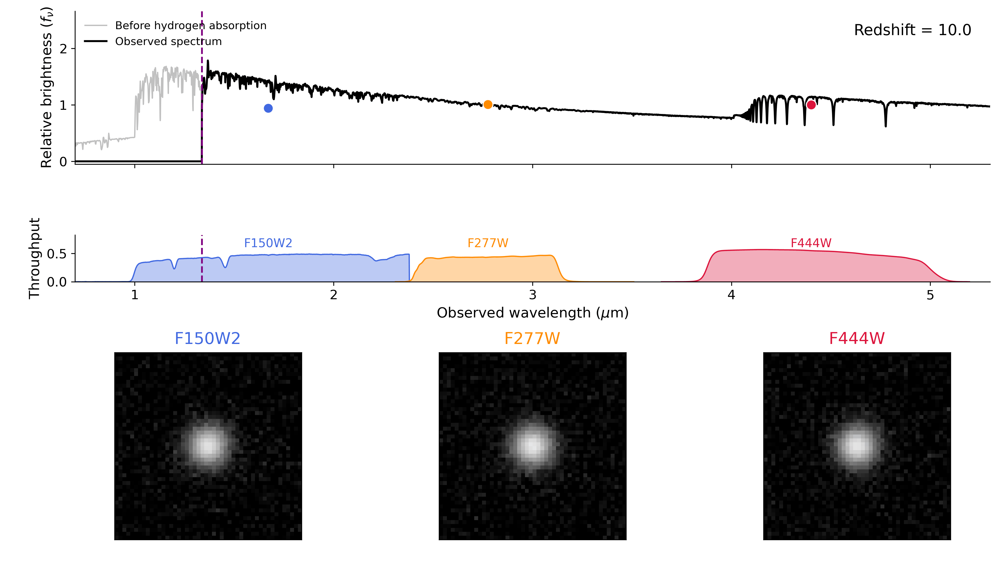

In [38]:
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
if SAVE_GIF:
    animation.save(GIF_PATH, writer=PillowWriter(fps=FPS), dpi=ANIMATION_DPI)
    print(f"Saved animation: {GIF_PATH}")

if SAVE_PREVIEW:
    preview_index = int(np.argmin(np.abs(REDSHIFTS - PREVIEW_REDSHIFT)))
    update_frame(preview_index)
    fig.savefig(PREVIEW_PATH, dpi=300, facecolor="white")
    print(f"Saved z = {REDSHIFTS[preview_index]:.1f} preview: {PREVIEW_PATH}")

if SAVE_GIF:
    display(DisplayImage(filename=str(GIF_PATH)))
elif SAVE_PREVIEW:
    display(DisplayImage(filename=str(PREVIEW_PATH)))